In [1]:
print("My MSc Data Science Thesis environment is ready!")

My MSc Data Science Thesis environment is ready!


In [2]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Both libraries are working successfully!")

Pandas version: 3.1.1
NumPy version: 2.5.5
Both libraries are working successfully!


In [3]:
import matplotlib
import matplotlib.pyplot as plt

print("Matplotlib version:", matplotlib.__version__)
print("Matplotlib is working successfully!")

Matplotlib is building the font cache; this may take a moment.


Matplotlib version: 3.11.2
Matplotlib is working successfully!


In [4]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Scikit-learn is working successfully!")

Scikit-learn version: 1.9.1
Scikit-learn is working successfully!


In [5]:
import sqlalchemy

print("SQLAlchemy version:", sqlalchemy.__version__)
print("SQLAlchemy is working successfully!")

SQLAlchemy version: 2.1.9
SQLAlchemy is working successfully!


In [6]:
import pymysql

print("PyMySQL version:", pymysql.__version__)
print("PyMySQL is working successfully!")

PyMySQL version: 2.2.8
PyMySQL is working successfully!


In [7]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

# Enter your MySQL root password securely
password = getpass("Enter MySQL password: ")

# Create database connection
db_url = URL.create(
    "mysql+pymysql",
    username="root",
    password=password,
    host="127.0.0.1",
    port=3306,
    database="tawos"
)

engine = create_engine(db_url)

# Test the connection
with engine.connect() as connection:
    result = connection.execute(
        text("SELECT COUNT(*) FROM `Issue`")
    )
    print("Total TAWOS issues:", result.scalar())

del password

Enter MySQL password:  ········


Total TAWOS issues: 458232


In [8]:
import pandas as pd
from sqlalchemy import text

# Count issues with valid resolution dates in each project
query = text("""
    SELECT
        Project_ID,
        COUNT(*) AS eligible_issues
    FROM `Issue`
    WHERE Creation_Date IS NOT NULL
      AND Resolution_Date IS NOT NULL
      AND Resolution_Date >= Creation_Date
    GROUP BY Project_ID
    ORDER BY eligible_issues DESC
""")

# Load the results into a Pandas DataFrame
project_counts = pd.read_sql(query, engine)

# Display summary
print("Number of projects:", len(project_counts))
print("Total eligible issues:", project_counts["eligible_issues"].sum())

display(project_counts.head(10))

Number of projects: 39
Total eligible issues: 352632


,Project_ID,eligible_issues
0,34,52249
1,33,43834
2,22,36268
3,18,35215
4,28,22570
5,12,19574
6,24,12842
7,14,12219
8,36,11292
9,20,10824


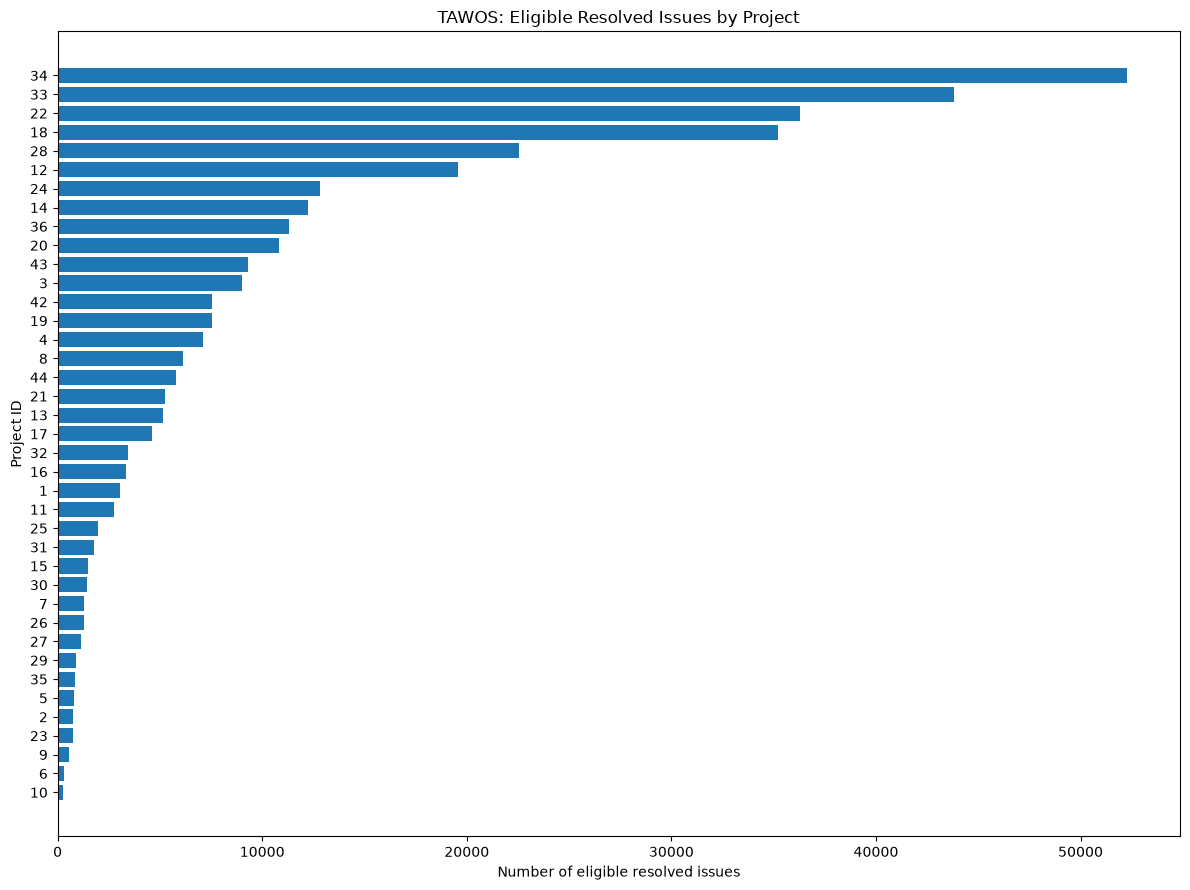

In [9]:
import matplotlib.pyplot as plt

# Sort projects by number of eligible issues
chart_data = project_counts.sort_values(
    "eligible_issues", ascending=True
)

plt.figure(figsize=(12, 9))

plt.barh(
    chart_data["Project_ID"].astype(str),
    chart_data["eligible_issues"]
)

plt.xlabel("Number of eligible resolved issues")
plt.ylabel("Project ID")
plt.title("TAWOS: Eligible Resolved Issues by Project")

plt.tight_layout()

# Save chart in your thesis results folder
plt.savefig(
    "../results/tawos_project_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
import pandas as pd
from sqlalchemy import text
from pathlib import Path

query = text("""
SELECT
    COUNT(*) AS total_issues,

    SUM(Resolution_Date IS NULL)
        AS missing_resolution_dates,

    SUM(
        Resolution_Date IS NOT NULL
        AND Resolution_Date >= Creation_Date
    ) AS eligible_resolved_issues,

    SUM(
        Resolution_Date IS NOT NULL
        AND Resolution_Date >= Creation_Date
        AND Resolution_Time_Minutes = 0
    ) AS zero_duration_issues,

    SUM(
        Resolution_Date IS NOT NULL
        AND Resolution_Date >= Creation_Date
        AND ABS(
            Resolution_Time_Minutes -
            TIMESTAMPDIFF(
                MINUTE,
                Creation_Date,
                Resolution_Date
            )
        ) > 1
    ) AS duration_mismatches

FROM `Issue`
""")

quality_summary = pd.read_sql(query, engine)

display(quality_summary.T)

# Save the results
Path("../results").mkdir(exist_ok=True)

quality_summary.to_csv(
    "../results/tawos_data_quality_summary.csv",
    index=False
)

print("Data quality summary saved successfully!")

,0
total_issues,458232.0
missing_resolution_dates,105600.0
eligible_resolved_issues,352632.0
zero_duration_issues,5583.0
duration_mismatches,74995.0


Data quality summary saved successfully!


In [11]:
from sqlalchemy import text
import pandas as pd

# Retrieve resolution durations from MySQL
query = text("""
    SELECT
        Resolution_Time_Minutes AS resolution_minutes
    FROM `Issue`
    WHERE Creation_Date IS NOT NULL
      AND Resolution_Date IS NOT NULL
      AND Resolution_Date >= Creation_Date
      AND Resolution_Time_Minutes IS NOT NULL
""")

resolution_data = pd.read_sql(query, engine)

# Convert minutes into days
resolution_data["resolution_days"] = (
    resolution_data["resolution_minutes"] / 1440
)

print("Issues analysed:", len(resolution_data))

print(
    "Zero-minute issues:",
    (resolution_data["resolution_minutes"] == 0).sum()
)

# Calculate resolution time statistics
summary = resolution_data["resolution_days"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(summary.round(2).to_frame("Resolution Time (Days)"))

Issues analysed: 352632
Zero-minute issues: 5583


,Resolution Time (Days)
count,352632.00
mean,368.62
std,680.90
min,0.00
25%,4.26
50%,35.06
75%,398.93
90%,1306.81
95%,1929.69
99%,3046.25


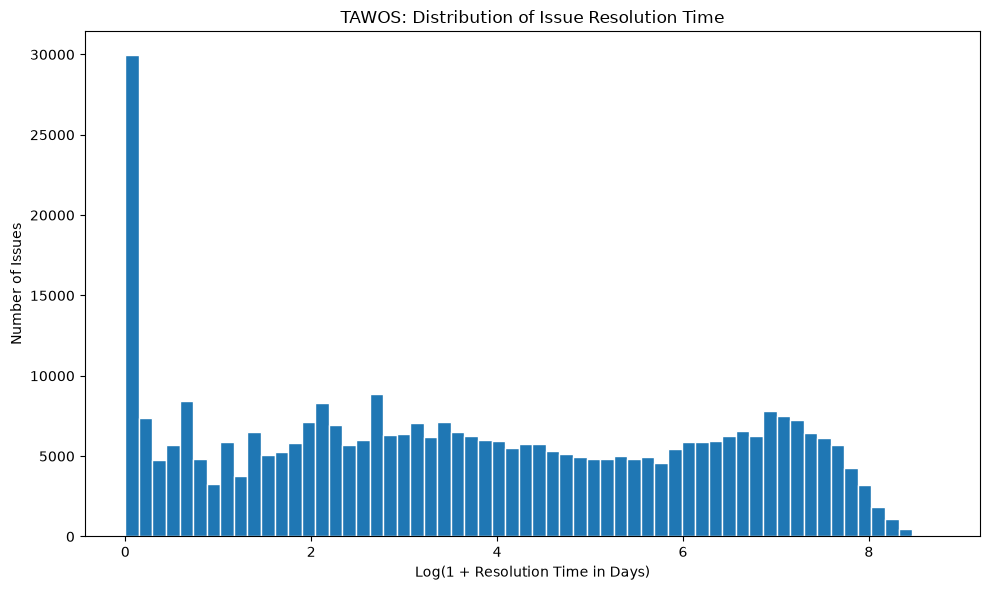

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Transform durations for visualization
log_resolution = np.log1p(
    resolution_data["resolution_days"]
)

plt.figure(figsize=(10, 6))

plt.hist(
    log_resolution,
    bins=60,
    edgecolor="white"
)

plt.xlabel("Log(1 + Resolution Time in Days)")
plt.ylabel("Number of Issues")
plt.title("TAWOS: Distribution of Issue Resolution Time")

plt.tight_layout()

# Save the chart
plt.savefig(
    "../results/tawos_resolution_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Initial Findings: Issue Resolution Time

The TAWOS dataset contains 352,632 issues with valid creation and resolution dates.

The median resolution time is 35.06 days, while the mean is 368.62 days, indicating a strongly right-skewed distribution.

The longest recorded resolution time is approximately 6,358 days.

A logarithmic transformation was applied for visualization to better display both short-duration and long-running issues.

These findings suggest that target transformation and robust evaluation metrics should be considered during model development.

The recorded resolution duration also shows some differences from timestamp-calculated durations. This issue requires further investigation before finalizing the prediction target.

In [13]:
from sqlalchemy import text
import pandas as pd

# Examine the Change_Log table structure
query = text("""
    SELECT
        COLUMN_NAME,
        DATA_TYPE
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE TABLE_SCHEMA = 'tawos'
      AND TABLE_NAME = 'Change_Log'
    ORDER BY ORDINAL_POSITION
""")

changelog_columns = pd.read_sql(query, engine)

display(changelog_columns)

,COLUMN_NAME,DATA_TYPE
0,ID,int
1,Field,varchar
2,From_Value,mediumtext
3,To_Value,mediumtext
4,From_String,mediumtext
5,To_String,mediumtext
6,Change_Type,varchar
7,Creation_Date,datetime
8,Author_ID,int
9,Issue_ID,int


In [14]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        Field,
        COUNT(*) AS change_count
    FROM Change_Log
    GROUP BY Field
    ORDER BY change_count DESC
    LIMIT 20
""")

changed_fields = pd.read_sql(query, engine)

display(changed_fields)

,Field,change_count
0,Workflow,1796669
1,status,1363475
2,Fix Version,599621
3,labels,477891
4,Rank,455498
5,Link,448089
6,resolution,416202
7,assignee,342509
8,UIS,334435
9,Component,306011


In [15]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        c.Issue_ID,
        i.Issue_Key,
        i.Creation_Date AS Issue_Created,
        c.Creation_Date AS Changed_At,
        c.From_String AS Previous_Priority,
        c.To_String AS New_Priority,
        i.Priority AS Stored_Priority
    FROM Change_Log c
    JOIN Issue i
        ON c.Issue_ID = i.ID
    WHERE c.Field = 'priority'
    LIMIT 10
""")

priority_changes = pd.read_sql(query, engine)

display(priority_changes)

,Issue_ID,Issue_Key,Issue_Created,Changed_At,Previous_Priority,New_Priority,Stored_Priority
0,72,XD-3761,2016-09-25 09:03:53,2016-09-28 06:31:25,Minor,Major,Major
1,73,XD-3760,2016-09-19 06:43:48,2016-09-19 18:09:00,Blocker,Minor,Minor
2,121,XD-3712,2015-11-27 04:51:43,2015-11-29 19:28:17,Major,Minor,Minor
3,180,XD-3653,2015-10-29 14:21:10,2015-10-29 14:21:20,Minor,Major,Major
4,191,XD-3642,2015-10-25 18:46:27,2015-10-26 15:04:31,Critical,Minor,Minor
5,446,XD-3387,2015-08-11 15:20:46,2015-08-14 10:03:13,Minor,Major,Major
6,674,XD-3157,2015-06-07 20:53:32,2015-06-07 22:42:20,Minor,Major,Major
7,690,XD-3141,2015-06-03 17:15:32,2015-06-04 10:29:57,Trivial,Critical,Critical
8,723,XD-3108,2015-05-26 19:42:51,2015-06-07 10:01:04,Critical,Major,Major
9,806,XD-3023,2015-05-01 11:15:00,2015-05-01 11:20:55,Minor,Critical,Critical


In [16]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        i.Issue_Key,
        i.Creation_Date AS Issue_Created,
        c.Creation_Date AS Changed_At,
        c.From_String AS Previous_Priority,
        c.To_String AS New_Priority,
        i.Priority AS Stored_Priority
    FROM Change_Log c
    JOIN Issue i
        ON c.Issue_ID = i.ID
    WHERE i.Issue_Key = 'XD-3761'
      AND LOWER(c.Field) = 'priority'
    ORDER BY c.Creation_Date ASC, c.ID ASC
""")

priority_history = pd.read_sql(query, engine)

display(priority_history)

,Issue_Key,Issue_Created,Changed_At,Previous_Priority,New_Priority,Stored_Priority
0,XD-3761,2016-09-25 09:03:53,2016-09-28 06:31:25,Minor,Major,Major


In [19]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        Project_ID,

        COUNT(*) AS total_issues,

        SUM(
            CASE
                WHEN Creation_Date IS NOT NULL
                 AND Resolution_Date IS NOT NULL
                 AND Resolution_Date >= Creation_Date
                THEN 1 ELSE 0
            END
        ) AS eligible_issues,

        SUM(
            CASE
                WHEN Resolution_Date IS NULL
                THEN 1 ELSE 0
            END
        ) AS missing_resolution_date,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN Resolution_Date IS NULL
                    THEN 1 ELSE 0
                END
            ) / COUNT(*),
            2
        ) AS missing_resolution_percentage

    FROM `Issue`
    GROUP BY Project_ID
    ORDER BY missing_resolution_percentage DESC
""")

project_eligibility = pd.read_sql(query, engine)

display(project_eligibility)

,Project_ID,total_issues,eligible_issues,missing_resolution_date,missing_resolution_percentage
0,6,1404,311.0,1093.0,77.85
1,21,23409,5247.0,18162.0,77.59
2,44,25669,5798.0,19871.0,77.41
3,5,1339,811.0,528.0,39.43
4,19,11702,7551.0,4151.0,35.47
5,27,1663,1157.0,506.0,30.43
6,4,10157,7091.0,3066.0,30.19
7,42,10060,7565.0,2495.0,24.80
8,8,8135,6133.0,2002.0,24.61
9,16,4311,3325.0,986.0,22.87


In [18]:
from sqlalchemy import text

# Close old database connections
engine.dispose()

# Test a fresh connection
with engine.connect() as connection:
    result = connection.execute(text("SELECT 1")).scalar()
    print("MySQL connection successful:", result)

MySQL connection successful: 1


In [20]:
project_eligibility.to_csv(
    "../results/tawos_project_eligibility_by_project.csv",
    index=False
)

print("Project eligibility analysis saved successfully!")

Project eligibility analysis saved successfully!


In [21]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        Status,
        COUNT(*) AS issue_count
    FROM `Issue`
    WHERE Resolution_Date IS NULL
    GROUP BY Status
    ORDER BY issue_count DESC
""")

missing_resolution_status = pd.read_sql(query, engine)

display(missing_resolution_status)

,Status,issue_count
0,Closed,28146
1,Gathering Interest,27232
2,Open,24658
3,Gathering Impact,8302
4,To Do,4909
...,...,...
66,Waiting for testing,1
67,Triaged,1
68,Waiting for Feedback,1
69,Automation,1


In [22]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        COALESCE(Resolution, '[NULL]') AS Resolution_Value,
        COUNT(*) AS Issue_Count
    FROM `Issue`
    WHERE Resolution_Date IS NULL
      AND Status = 'Closed'
    GROUP BY Resolution
    ORDER BY Issue_Count DESC
""")

closed_issue_resolutions = pd.read_sql(query, engine)

display(closed_issue_resolutions)

,Resolution_Value,Issue_Count
0,Fixed,7333
1,Won't Fix,6218
2,Won't Do,3071
3,Duplicate,2558
4,Answered,2267
5,Cannot Reproduce,1457
6,Support Request,1032
7,Complete,1009
8,Timed out,917
9,Obsolete,552


In [23]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        COUNT(*) AS total_closed_missing_date,

        SUM(
            CASE WHEN Resolution_Time_Minutes IS NULL
            THEN 1 ELSE 0 END
        ) AS missing_duration,

        SUM(
            CASE WHEN Resolution_Time_Minutes = 0
            THEN 1 ELSE 0 END
        ) AS zero_duration,

        SUM(
            CASE WHEN Resolution_Time_Minutes > 0
            THEN 1 ELSE 0 END
        ) AS positive_duration,

        SUM(
            CASE WHEN Resolution_Time_Minutes < 0
            THEN 1 ELSE 0 END
        ) AS negative_duration

    FROM `Issue`
    WHERE Status = 'Closed'
      AND Resolution_Date IS NULL
""")

closed_duration_check = pd.read_sql(query, engine)

display(closed_duration_check)

,total_closed_missing_date,missing_duration,zero_duration,positive_duration,negative_duration
0,28146,0.0,28146.0,0.0,0.0


In [24]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        COUNT(*) AS total_missing_resolution_date,

        SUM(
            CASE WHEN Resolution_Time_Minutes IS NULL
            THEN 1 ELSE 0 END
        ) AS missing_duration,

        SUM(
            CASE WHEN Resolution_Time_Minutes = 0
            THEN 1 ELSE 0 END
        ) AS zero_duration,

        SUM(
            CASE WHEN Resolution_Time_Minutes > 0
            THEN 1 ELSE 0 END
        ) AS positive_duration,

        SUM(
            CASE WHEN Resolution_Time_Minutes < 0
            THEN 1 ELSE 0 END
        ) AS negative_duration

    FROM `Issue`
    WHERE Resolution_Date IS NULL
""")

all_missing_duration_check = pd.read_sql(query, engine)

display(all_missing_duration_check)

,total_missing_resolution_date,missing_duration,zero_duration,positive_duration,negative_duration
0,105600,0.0,105600.0,0.0,0.0


In [25]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        COALESCE(
            NULLIF(TRIM(Resolution), ''),
            '[NULL/EMPTY]'
        ) AS Resolution_Value,
        COUNT(*) AS Issue_Count

    FROM `Issue`

    WHERE Resolution_Date IS NULL

    GROUP BY Resolution_Value
    ORDER BY Issue_Count DESC
    LIMIT 20
""")

missing_date_resolutions = pd.read_sql(query, engine)

display(missing_date_resolutions)

,Resolution_Value,Issue_Count
0,[NULL/EMPTY],77498
1,Fixed,7335
2,Won't Fix,6218
3,Won't Do,3071
4,Duplicate,2558
5,Answered,2267
6,Cannot Reproduce,1457
7,Support Request,1032
8,Complete,1009
9,Timed out,917


In [26]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        CASE
            WHEN Status = 'Closed'
            THEN 'Closed'
            ELSE 'Other Statuses'
        END AS status_group,

        CASE
            WHEN NULLIF(TRIM(Resolution), '') IS NULL
            THEN 'Missing Resolution Label'
            ELSE 'Resolution Label Present'
        END AS resolution_group,

        COUNT(*) AS issue_count

    FROM `Issue`
    WHERE Resolution_Date IS NULL

    GROUP BY status_group, resolution_group
    ORDER BY status_group, resolution_group
""")

missing_date_groups = pd.read_sql(query, engine)

display(missing_date_groups)

,status_group,resolution_group,issue_count
0,Closed,Missing Resolution Label,49
1,Closed,Resolution Label Present,28097
2,Other Statuses,Missing Resolution Label,77449
3,Other Statuses,Resolution Label Present,5


## Issue Eligibility and Potential Selection Bias

### Initial Eligibility Criteria

The TAWOS dataset contains 458,232 issues across 39 projects.

An issue was initially considered eligible for resolution-time
regression if:

- Creation_Date is not NULL.
- Resolution_Date is not NULL.
- Resolution_Date is greater than or equal to Creation_Date.

Using these criteria, 352,632 issues were eligible (76.95%).

The remaining 105,600 issues (23.05%) had missing
resolution dates.

### Investigation of Excluded Issues

All 105,600 issues without resolution dates had a stored
Resolution_Time_Minutes value of zero.

Further investigation identified:

- 77,498 issues with missing resolution labels.
- 28,102 issues with recorded resolution labels.
- 28,146 issues marked Closed despite missing resolution dates.
- Of the Closed issues, 28,097 had resolution labels and
  49 had missing resolution labels.

These findings indicate that the excluded population
contains both issues without recorded resolution outcomes
and issues with recorded outcomes but unavailable
resolution timestamps.

Zero stored duration was not treated as evidence of
instantaneous resolution.

### Selection Bias Considerations

Missing resolution dates are unevenly distributed across
projects, indicating a potential risk of selection bias.

The initial regression dataset is therefore restricted to
issues with observable resolution durations.

This limitation will be considered when interpreting
cross-project generalizability results.

Further investigation of observation periods and feature
availability is required before finalizing the methodology.

In [27]:
from sqlalchemy import text
import pandas as pd

query = text("""
    SELECT
        COUNT(*) AS total_priority_changes,

        COUNT(DISTINCT c.Issue_ID)
            AS issues_with_priority_changes,

        SUM(
            CASE
                WHEN c.From_String IS NULL
                  OR TRIM(c.From_String) = ''
                THEN 1 ELSE 0
            END
        ) AS missing_previous_priority,

        SUM(
            CASE
                WHEN c.Creation_Date < i.Creation_Date
                THEN 1 ELSE 0
            END
        ) AS changes_before_issue_creation,

        SUM(
            CASE
                WHEN c.Creation_Date >= i.Creation_Date
                THEN 1 ELSE 0
            END
        ) AS changes_at_or_after_creation

    FROM `Change_Log` c
    JOIN `Issue` i
        ON c.Issue_ID = i.ID
    WHERE c.Field = 'priority'
""")

priority_audit = pd.read_sql(query, engine)

display(priority_audit)

,total_priority_changes,issues_with_priority_changes,missing_previous_priority,changes_before_issue_creation,changes_at_or_after_creation
0,110537,95249,5584.0,0.0,110537.0


In [28]:
from sqlalchemy import text
import pandas as pd

query = text("""
    WITH ranked_changes AS (
        SELECT
            c.Issue_ID,
            c.From_String,
            i.Priority AS Stored_Priority,

            ROW_NUMBER() OVER (
                PARTITION BY c.Issue_ID
                ORDER BY c.Creation_Date ASC, c.ID ASC
            ) AS change_number

        FROM `Change_Log` c
        JOIN `Issue` i
            ON c.Issue_ID = i.ID

        WHERE c.Field = 'priority'
    )

    SELECT
        COUNT(*) AS issues_with_priority_changes,

        SUM(
            CASE
                WHEN From_String IS NULL
                  OR TRIM(From_String) = ''
                THEN 1 ELSE 0
            END
        ) AS missing_earliest_priority,

        SUM(
            CASE
                WHEN From_String IS NOT NULL
                 AND TRIM(From_String) <> ''
                THEN 1 ELSE 0
            END
        ) AS available_earliest_priority,

        SUM(
            CASE
                WHEN From_String IS NOT NULL
                 AND TRIM(From_String) <> ''
                 AND NOT (From_String <=> Stored_Priority)
                THEN 1 ELSE 0
            END
        ) AS initial_differs_from_stored

    FROM ranked_changes
    WHERE change_number = 1
""")

earliest_priority_audit = pd.read_sql(query, engine)

display(earliest_priority_audit)

,issues_with_priority_changes,missing_earliest_priority,available_earliest_priority,initial_differs_from_stored
0,95249,5406.0,89843.0,88688.0


In [29]:
from sqlalchemy import text
import pandas as pd

query = text("""
    WITH latest_changes AS (
        SELECT
            c.Issue_ID,
            c.To_String,
            i.Priority AS Stored_Priority,

            ROW_NUMBER() OVER (
                PARTITION BY c.Issue_ID
                ORDER BY c.Creation_Date DESC, c.ID DESC
            ) AS change_number

        FROM `Change_Log` c
        JOIN `Issue` i
            ON c.Issue_ID = i.ID

        WHERE c.Field = 'priority'
    )

    SELECT
        COUNT(*) AS issues_checked,

        SUM(
            CASE
                WHEN To_String IS NULL
                  OR TRIM(To_String) = ''
                THEN 1 ELSE 0
            END
        ) AS missing_latest_priority,

        SUM(
            CASE
                WHEN TRIM(To_String) <> ''
                 AND TRIM(To_String) = TRIM(Stored_Priority)
                THEN 1 ELSE 0
            END
        ) AS latest_matches_stored,

        SUM(
            CASE
                WHEN To_String IS NOT NULL
                 AND TRIM(To_String) <> ''
                 AND NOT (
                     TRIM(To_String) <=> TRIM(Stored_Priority)
                 )
                THEN 1 ELSE 0
            END
        ) AS latest_differs_from_stored

    FROM latest_changes
    WHERE change_number = 1
""")

latest_priority_audit = pd.read_sql(query, engine)

display(latest_priority_audit)

,issues_checked,missing_latest_priority,latest_matches_stored,latest_differs_from_stored
0,95249,29870.0,53909.0,11470.0


In [30]:
from sqlalchemy import text
import pandas as pd

query = text("""
    WITH latest_changes AS (
        SELECT
            c.Issue_ID,
            i.Issue_Key,
            c.Creation_Date AS Changed_At,
            c.Change_Type,
            c.From_String,
            c.To_String,
            c.From_Value,
            c.To_Value,
            i.Priority AS Stored_Priority,

            ROW_NUMBER() OVER (
                PARTITION BY c.Issue_ID
                ORDER BY c.Creation_Date DESC, c.ID DESC
            ) AS rn

        FROM `Change_Log` c
        JOIN `Issue` i
            ON c.Issue_ID = i.ID
        WHERE c.Field = 'priority'
    )

    SELECT
        Issue_Key,
        Changed_At,
        Change_Type,
        From_String,
        To_String,
        From_Value,
        To_Value,
        Stored_Priority

    FROM latest_changes
    WHERE rn = 1
      AND (
          To_String IS NULL
          OR TRIM(To_String) = ''
      )
    LIMIT 10
""")

missing_latest_samples = pd.read_sql(query, engine)

display(missing_latest_samples)

,Issue_Key,Changed_At,Change_Type,From_String,To_String,From_Value,To_Value,Stored_Priority
0,ALOY-1143,2014-08-28 18:59:10,OTHER,None,None,6,None,
1,ALOY-448,2012-12-20 22:05:12,OTHER,None,None,6,None,
2,CWD-5481,2020-02-03 13:18:12,OTHER,Low,None,4,None,
3,CWD-5480,2020-02-03 13:20:12,OTHER,Low,None,4,None,
4,CWD-5441,2020-06-10 08:52:40,OTHER,Low,None,4,None,
5,CWD-5440,2020-06-10 08:48:08,OTHER,Low,None,4,None,
6,CWD-5383,2020-06-24 08:06:44,OTHER,Low,None,4,None,
7,CWD-5357,2020-02-03 12:57:04,OTHER,Medium,None,3,None,
8,CWD-5335,2020-04-01 08:15:27,OTHER,Low,None,4,None,
9,CWD-5211,2020-06-24 08:05:43,OTHER,Low,None,4,None,


In [31]:
from sqlalchemy import text
import pandas as pd

query = text("""
    WITH latest_changes AS (
        SELECT
            c.Issue_ID,
            c.To_String,
            c.To_Value,
            i.Priority AS Stored_Priority,

            ROW_NUMBER() OVER (
                PARTITION BY c.Issue_ID
                ORDER BY c.Creation_Date DESC, c.ID DESC
            ) AS rn

        FROM `Change_Log` c
        JOIN `Issue` i
            ON c.Issue_ID = i.ID

        WHERE c.Field = 'priority'
    )

    SELECT
        COUNT(*) AS missing_latest_priority,

        SUM(
            CASE
                WHEN Stored_Priority IS NULL
                  OR TRIM(Stored_Priority) = ''
                THEN 1 ELSE 0
            END
        ) AS stored_priority_also_missing,

        SUM(
            CASE
                WHEN Stored_Priority IS NOT NULL
                 AND TRIM(Stored_Priority) <> ''
                THEN 1 ELSE 0
            END
        ) AS stored_priority_present,

        SUM(
            CASE
                WHEN To_Value IS NULL
                  OR TRIM(To_Value) = ''
                THEN 1 ELSE 0
            END
        ) AS to_value_also_missing

    FROM latest_changes
    WHERE rn = 1
      AND (
          To_String IS NULL
          OR TRIM(To_String) = ''
      )
""")

priority_missing_consistency = pd.read_sql(query, engine)

display(priority_missing_consistency)

,missing_latest_priority,stored_priority_also_missing,stored_priority_present,to_value_also_missing
0,29870,29870.0,0.0,29870.0


In [32]:
from sqlalchemy import text
import pandas as pd

query = text("""
    WITH latest_changes AS (
        SELECT
            c.Issue_ID,
            i.Issue_Key,
            i.Project_ID,
            c.Creation_Date AS Changed_At,
            c.Change_Type,
            c.From_String,
            c.To_String,
            c.To_Value,
            i.Priority AS Stored_Priority,

            ROW_NUMBER() OVER (
                PARTITION BY c.Issue_ID
                ORDER BY c.Creation_Date DESC, c.ID DESC
            ) AS rn

        FROM `Change_Log` c
        JOIN `Issue` i
            ON c.Issue_ID = i.ID

        WHERE c.Field = 'priority'
    )

    SELECT
        Issue_Key,
        Project_ID,
        Changed_At,
        Change_Type,
        From_String,
        To_String,
        To_Value,
        Stored_Priority

    FROM latest_changes

    WHERE rn = 1
      AND NULLIF(TRIM(To_String), '') IS NOT NULL
      AND NOT (
          NULLIF(TRIM(To_String), '')
          <=>
          NULLIF(TRIM(Stored_Priority), '')
      )

    LIMIT 10
""")

priority_mismatch_samples = pd.read_sql(query, engine)

display(priority_mismatch_samples)

,Issue_Key,Project_ID,Changed_At,Change_Type,From_String,To_String,To_Value,Stored_Priority
0,USERGRID-1248,5,2016-09-03 00:20:24,OTHER,Major,Critical,2,Major
1,APSTUD-7539,8,2011-04-12 11:54:21,OTHER,Major,Minor,4,Low
2,APSTUD-3707,8,2011-04-12 11:54:33,OTHER,Major,Minor,4,Low
3,APSTUD-2705,8,2011-06-10 04:08:01,OTHER,Trivial,Major,3,Medium
4,APSTUD-2702,8,2011-06-09 07:46:58,OTHER,Trivial,Major,3,Medium
5,APSTUD-2698,8,2011-06-09 07:46:52,OTHER,Trivial,Minor,4,Low
6,APSTUD-2695,8,2011-06-09 07:46:45,OTHER,Major,Minor,4,Low
7,APSTUD-2694,8,2011-06-09 07:46:42,OTHER,Major,Minor,4,Low
8,APSTUD-2688,8,2011-06-09 07:46:28,OTHER,Major,Minor,4,Low
9,APSTUD-2682,8,2011-06-09 07:45:54,OTHER,Major,Minor,4,Low


In [33]:
from sqlalchemy import text
import pandas as pd

query = text("""
    WITH latest_changes AS (
        SELECT
            i.Project_ID,
            c.Issue_ID,
            c.To_String,
            i.Priority AS Stored_Priority,

            ROW_NUMBER() OVER (
                PARTITION BY c.Issue_ID
                ORDER BY c.Creation_Date DESC, c.ID DESC
            ) AS rn

        FROM `Change_Log` c
        JOIN `Issue` i
            ON c.Issue_ID = i.ID

        WHERE c.Field = 'priority'
    )

    SELECT
        Project_ID,
        To_String AS Historical_Priority,
        Stored_Priority,
        COUNT(*) AS Issue_Count

    FROM latest_changes

    WHERE rn = 1
      AND NULLIF(TRIM(To_String), '') IS NOT NULL
      AND NOT (
          NULLIF(TRIM(To_String), '')
          <=>
          NULLIF(TRIM(Stored_Priority), '')
      )

    GROUP BY
        Project_ID,
        To_String,
        Stored_Priority

    ORDER BY Issue_Count DESC
    LIMIT 20
""")

priority_mappings = pd.read_sql(query, engine)

display(priority_mappings)

,Project_ID,Historical_Priority,Stored_Priority,Issue_Count
0,18,Major,Medium,1342
1,22,Major,Medium,1213
2,22,Minor,Low,788
3,18,Minor,Low,787
4,22,Critical,High,509
5,14,Major,Medium,436
6,18,Critical,High,397
7,20,Major,Medium,368
8,28,Major,,269
9,19,Major,Medium,229


In [34]:
from sqlalchemy import text
import pandas as pd

query = text("""
    WITH latest_changes AS (
        SELECT
            c.Issue_ID,
            c.To_String,
            i.Priority AS Stored_Priority,

            ROW_NUMBER() OVER (
                PARTITION BY c.Issue_ID
                ORDER BY c.Creation_Date DESC, c.ID DESC
            ) AS rn

        FROM `Change_Log` c
        JOIN `Issue` i
            ON c.Issue_ID = i.ID

        WHERE c.Field = 'priority'
    ),

    mismatches AS (
        SELECT
            To_String,
            Stored_Priority
        FROM latest_changes
        WHERE rn = 1
          AND NULLIF(TRIM(To_String), '') IS NOT NULL
          AND NOT (
              NULLIF(TRIM(To_String), '')
              <=>
              NULLIF(TRIM(Stored_Priority), '')
          )
    )

    SELECT
        CASE
            WHEN
                (TRIM(To_String) = 'Major'
                 AND TRIM(Stored_Priority) = 'Medium')
                OR
                (TRIM(To_String) = 'Minor'
                 AND TRIM(Stored_Priority) = 'Low')
                OR
                (TRIM(To_String) = 'Critical'
                 AND TRIM(Stored_Priority) = 'High')
                OR
                (TRIM(To_String) = 'Trivial'
                 AND TRIM(Stored_Priority) = 'Low')
            THEN 'Candidate Label Mapping'

            WHEN Stored_Priority IS NULL
                 OR TRIM(Stored_Priority) = ''
            THEN 'Stored Priority Missing'

            ELSE 'Other Inconsistency'
        END AS mismatch_category,

        COUNT(*) AS issue_count

    FROM mismatches

    GROUP BY mismatch_category
    ORDER BY issue_count DESC
""")

priority_mismatch_categories = pd.read_sql(query, engine)

display(priority_mismatch_categories)

,mismatch_category,issue_count
0,Candidate Label Mapping,9193
1,Stored Priority Missing,1309
2,Other Inconsistency,968


## Leakage-Free Feature Audit: Priority

### Objective

Determine whether the Priority attribute can be reliably
used for predicting issue resolution time at issue creation.

### Findings

The TAWOS Change_Log analysis identified:

- 110,537 recorded priority-change events.
- 95,249 distinct issues with priority changes.
- 5,406 issues with missing previous-priority values
  in their earliest recorded priority change.
- 29,870 issues where both the latest historical priority
  and the stored priority were missing.
- 11,470 issues where the latest nonempty historical
  priority differed from the stored priority.

The 11,470 mismatches were categorized as:

- 9,193 candidate priority-label mappings (80.15%).
- 1,309 missing stored priority values (11.41%).
- 968 other inconsistencies (8.44%).

The candidate mappings suggest possible differences
between historical and stored priority naming conventions.
However, these mappings have not been fully validated.

### Leakage Risk

The Priority attribute can change after issue creation.
Therefore, using its final stored value may introduce
information unavailable at prediction time.

Although the Change_Log table provides historical values,
complete and consistent reconstruction of creation-time
priority has not yet been established.

### Provisional Modelling Decision

EXCLUDE Priority from the initial leakage-free model.

This decision follows the supervisor's recommendation to
exclude features whose original creation-time values
cannot be recovered reliably.

Priority reconstruction may be revisited in a later
sensitivity analysis if its reliability can be demonstrated.